**Understanding Dataset**


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("SuperMarket Analysis.csv")
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3


In [8]:
df.head(15)

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,1:08:00 PM,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,Giza,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29:00 AM,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,1:23:00 PM,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,8:33:00 PM,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37:00 AM,Ewallet,604.17,4.761905,30.2085,5.3
5,699-14-3026,Giza,Naypyitaw,Member,Female,Electronic accessories,85.39,7,29.8865,627.6165,3/25/2019,6:30:00 PM,Ewallet,597.73,4.761905,29.8865,4.1
6,355-53-5943,Alex,Yangon,Member,Female,Electronic accessories,68.84,6,20.6520,433.6920,2/25/2019,2:36:00 PM,Ewallet,413.04,4.761905,20.6520,5.8
7,315-22-5665,Giza,Naypyitaw,Member,Female,Home and lifestyle,73.56,10,36.7800,772.3800,2/24/2019,11:38:00 AM,Ewallet,735.60,4.761905,36.7800,8.0
8,665-32-9167,Alex,Yangon,Member,Female,Health and beauty,36.26,2,3.6260,76.1460,1/10/2019,5:15:00 PM,Credit card,72.52,4.761905,3.6260,7.2
9,692-92-5582,Cairo,Mandalay,Member,Female,Food and beverages,54.84,3,8.2260,172.7460,2/20/2019,1:27:00 PM,Credit card,164.52,4.761905,8.2260,5.9


In [41]:
numeric_columns = [
    col for col in df.columns
    if df[col].dtype in ["int64", "float64"]
]

print(numeric_columns)

['Unit price', 'Quantity', 'Tax 5%', 'Sales', 'cogs', 'gross margin percentage', 'gross income', 'Rating']


In [42]:
print("\nCategorical Columns:")
print(df.select_dtypes(include="object").columns.tolist())


Categorical Columns:
['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender', 'Product line', 'Time', 'Payment', 'Purchase Size', 'Rating Category', 'Day_Type', 'Branch Code_x', 'Branch Code_y', 'Branch Code']


This data set is about superstore sales in Myanmar, it contains information about product categories, customer types, cities, prices, quantities, payment methods, sales, and customer ratings.

**3 questions:**
1- Which product category generates the highest total sales?

2- Which city has the highest average transaction value?

3- Which payment method is most commonly used by customers?

In [10]:
print(df.shape)
print(df.info())
print(df.describe())

(1000, 17)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Invoice ID               1000 non-null   object 
 1   Branch                   1000 non-null   object 
 2   City                     1000 non-null   object 
 3   Customer type            1000 non-null   object 
 4   Gender                   1000 non-null   object 
 5   Product line             1000 non-null   object 
 6   Unit price               1000 non-null   float64
 7   Quantity                 1000 non-null   int64  
 8   Tax 5%                   1000 non-null   float64
 9   Sales                    1000 non-null   float64
 10  Date                     1000 non-null   object 
 11  Time                     1000 non-null   object 
 12  Payment                  1000 non-null   object 
 13  cogs                     1000 non-null   float64
 14  gross margin p

**Transforming Dataset**

In [11]:

df.isna().sum()


,0
Invoice ID,0
Branch,0
City,0
Customer type,0
Gender,0
Product line,0
Unit price,0
Quantity,0
Tax 5%,0
Sales,0


In [38]:
# Filtering transactions with quantity

filtered_df = df[(df["Quantity"] > 5) & (df["Sales"] > 300)]
filtered_df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,...,cogs,gross margin percentage,gross income,Rating,Purchase Size,Rating Category,Day_Type,Branch Code_x,Branch Code_y,Branch Code
0,750-67-8428,Alex,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,...,522.83,4.761905,26.1415,9.1,Large,High,Weekend,A,A,A
2,631-41-3108,Alex,Yangon,Normal,Female,Home and lifestyle,46.33,7,16.2155,340.5255,...,324.31,4.761905,16.2155,7.4,Large,High,Weekend,A,A,A
3,123-19-1176,Alex,Yangon,Member,Female,Health and beauty,58.22,8,23.2880,489.0480,...,465.76,4.761905,23.2880,8.4,Large,High,Weekend,A,A,A
4,373-73-7910,Alex,Yangon,Member,Female,Sports and travel,86.31,7,30.2085,634.3785,...,604.17,4.761905,30.2085,5.3,Large,Low,Weekday,A,A,A
5,699-14-3026,Giza,Naypyitaw,Member,Female,Electronic accessories,85.39,7,29.8865,627.6165,...,597.73,4.761905,29.8865,4.1,Large,Low,Weekday,B,B,B


In [39]:
# Sort transactions by City and Sales

sorted_df = df.sort_values(
    by=["City", "Sales"],
    ascending=[True, False]
)

sorted_df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Sales,...,cogs,gross margin percentage,gross income,Rating,Purchase Size,Rating Category,Day_Type,Branch Code_x,Branch Code_y,Branch Code
996,303-96-2227,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,...,973.80,4.761905,48.6900,4.4,Large,Low,Weekend,C,C,C
792,744-16-7898,Cairo,Mandalay,Normal,Female,Home and lifestyle,97.37,10,48.6850,1022.3850,...,973.70,4.761905,48.6850,4.9,Large,Low,Weekday,C,C,C
122,219-22-9386,Cairo,Mandalay,Member,Female,Sports and travel,99.96,9,44.9820,944.6220,...,899.64,4.761905,44.9820,4.2,Large,Low,Weekend,C,C,C
209,817-69-8206,Cairo,Mandalay,Normal,Female,Electronic accessories,99.73,9,44.8785,942.4485,...,897.57,4.761905,44.8785,6.5,Large,Low,Weekend,C,C,C
96,766-85-7061,Cairo,Mandalay,Member,Female,Health and beauty,87.87,10,43.9350,922.6350,...,878.70,4.761905,43.9350,5.1,Large,Low,Weekday,C,C,C


In [12]:
# Converting Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], format="mixed")
df["Date"].head()

,Date
0,2019-01-05
1,2019-03-08
2,2019-03-03
3,2019-01-27
4,2019-02-08


In [13]:
#creating new column
df["Purchase Size"] = df["Quantity"].apply(
    lambda x: "Large" if x >= 6 else "Small"
)

df[["Quantity", "Purchase Size"]].head()

,Quantity,Purchase Size
0,7,Large
1,5,Small
2,7,Large
3,8,Large
4,7,Large


In [14]:
#new column using named function
def rating_category(rating):
    if rating >= 7:
        return "High"
    else:
        return "Low"

df["Rating Category"] = df["Rating"].apply(rating_category)

df[["Rating", "Rating Category"]].head()

,Rating,Rating Category
0,9.1,High
1,9.6,High
2,7.4,High
3,8.4,High
4,5.3,Low


In [15]:
#using np.where
df["Day_Type"] = np.where(
    df["Date"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

df[["Date", "Day_Type"]].head()

,Date,Day_Type
0,2019-01-05,Weekend
1,2019-03-08,Weekday
2,2019-03-03,Weekend
3,2019-01-27,Weekend
4,2019-02-08,Weekday


In [16]:
#using group by
category_sales = df.groupby("Product line")["Sales"].sum()

category_sales

category_sales.sort_values(ascending=False)

,Sales
Product line,
Food and beverages,56144.8440
Sports and travel,55122.8265
Electronic accessories,54337.5315
Fashion accessories,54305.8950
Home and lifestyle,53861.9130
Health and beauty,49193.7390


In [17]:

city_sales = df.groupby("City")["Sales"].agg(["mean", "sum", "count"])
city_sales.sort_values(by="mean", ascending=False)

,mean,sum,count
City,,,
Naypyitaw,337.099715,110568.7065,328
Mandalay,319.872506,106197.6720,332
Yangon,312.354031,106200.3705,340


**Visualization**

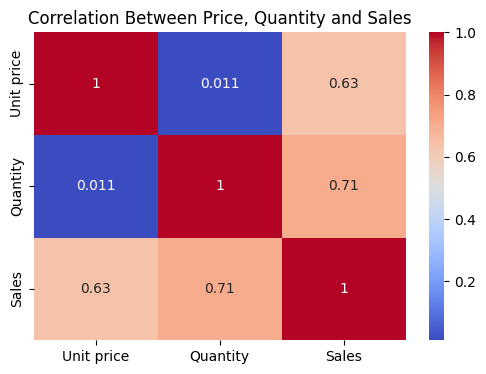

In [18]:

columns = ["Unit price", "Quantity", "Sales"]

correlation = df[columns].corr()

plt.figure(figsize=(6, 4))
sns.heatmap(correlation, annot=True, cmap="coolwarm")

plt.title("Correlation Between Price, Quantity and Sales")
plt.show()


Quantity and Sales have a strong positive correlation (0.71), while Unit Price and Sales also show a positive correlation (0.63). However, Unit Price and Quantity have almost no correlation (0.011). This indicates that both price and quantity are related to sales, with quantity showing a stronger relationship.

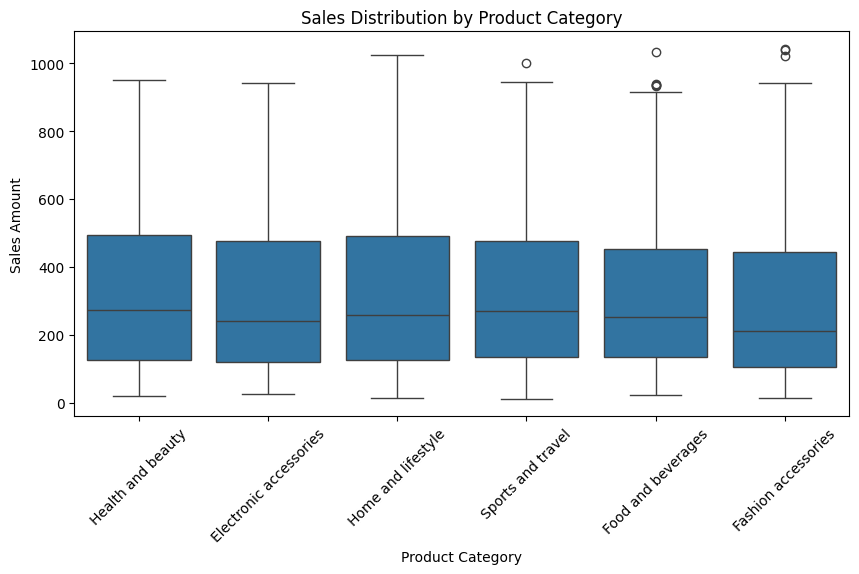

In [20]:
#!
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x="Product line", y="Sales")

plt.title("Sales Distribution by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)

plt.show()

The boxplot shows that median transaction sales are almost similar across product categories. However, some categories mainly Fashion accessories, Food and beverages and Sports and travel contain unusually highvalue transactions. So these potential outliers suggest that few purchases are significantly higher than typical transactions within their respective categories.

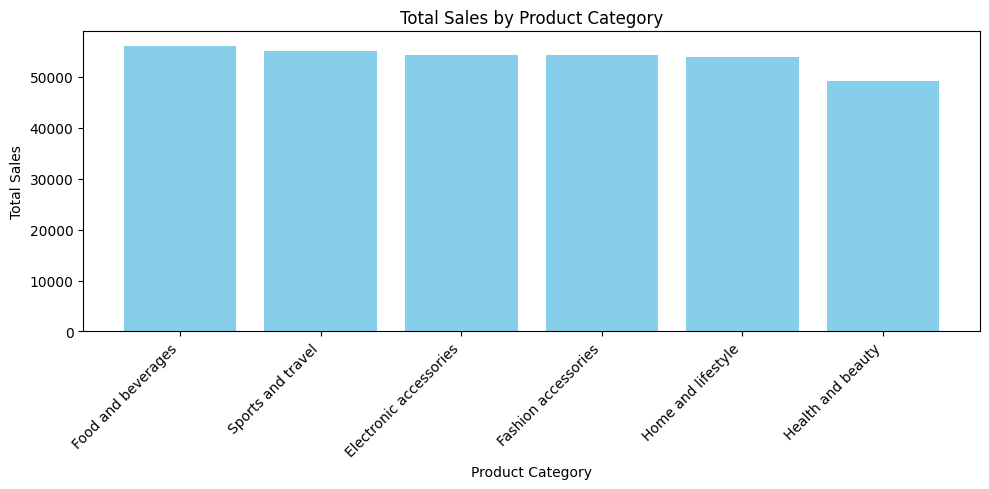

In [21]:
#fig#2
category_sales = df.groupby("Product line")["Sales"].sum()
category_sales = category_sales.sort_values(ascending=False)
plt.figure(figsize=(10, 5))

plt.bar(category_sales.index, category_sales.values, color="skyblue")

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

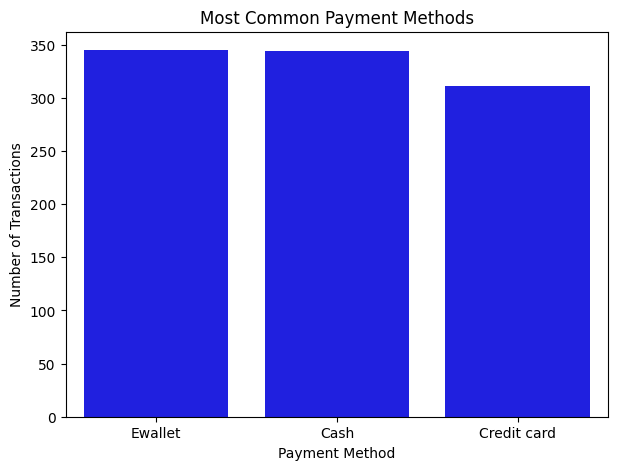

In [25]:
#Fig#3
payment_count = df["Payment"].value_counts()
plt.figure(figsize=(7, 5))
sns.barplot(x=payment_count.index, y=payment_count.values, color="blue")
plt.title("Most Common Payment Methods")
plt.xlabel("Payment Method")
plt.ylabel("Number of Transactions")

plt.show()

Fig 2&3 answers are questions 1&3, Food & Beverages have highest total sales across category & health and beauty have lowest total sales.. This suggests that Food and beverages contributed the most to the supermarket's overall sales revenue during the period analyzed.

---
customers prefers ewallet and cash more as mode of payment rather than creditcard. This indicates that digital wallet payments are a popular choice among customers in the dataset.



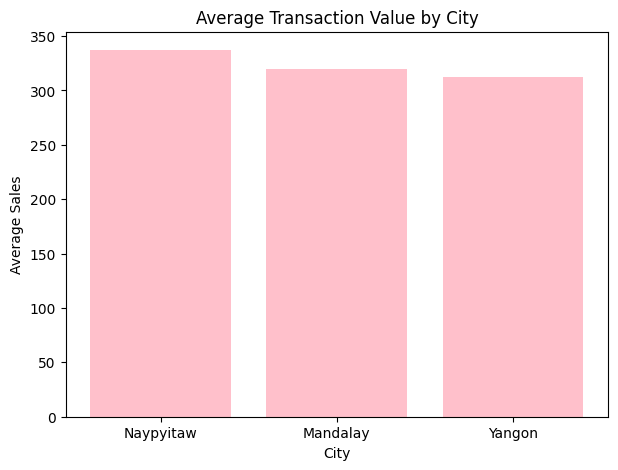

In [28]:
# Average Sales by City

city_avg = df.groupby("City")["Sales"].mean()
city_avg = city_avg.sort_values(ascending=False)

plt.figure(figsize=(7, 5))

plt.bar(city_avg.index, city_avg.values, color="pink")

plt.title("Average Transaction Value by City")
plt.xlabel("City")
plt.ylabel("Average Sales")

plt.show()

The bar chart compares the average transaction value across the 3 cities. Naypyitaw has the highest average transaction value of approximately 337.10, indicating that customers in this city spend more per transaction on average compared to the other two cities.

In [32]:
# Requirement 14: Create second DataFrame

branch_info = pd.DataFrame({
    "Branch": ["Alex", "Giza", "Cairo"],
    "Branch Code": ["A", "B", "C"]
})

branch_info

,Branch,Branch Code
0,Alex,A
1,Giza,B
2,Cairo,C


In [35]:
# Merge branch codes
df = df.merge(branch_info, on="Branch", how="left")
df[["Branch", "Branch Code", "City"]].head()

,Branch,Branch Code,City
0,Alex,A,Yangon
1,Giza,B,Naypyitaw
2,Alex,A,Yangon
3,Alex,A,Yangon
4,Alex,A,Yangon


## Final Conclusions

The analysis of 1,000 supermarket transactions revealed the following findings:

1. **Food and beverages** generated the highest total sales (56,144.84).
2. **Naypyitaw** had the highest average transaction value (337.10).
3. **Ewallet** was the most commonly used payment method.
4. Quantity and unit price were both positively correlated with sales with quantity showing the stronger relationship.
5. Sales varied across product categories, with some unusually high value transactions identified as outliers.

Overall this analysis helps identify top performing product categories, customer spending pattern and payment preferences.. providing useful insights for supermarket decision making.